In [6]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (silhouette_score, davies_bouldin_score, calinski_harabasz_score,
                             adjusted_rand_score, normalized_mutual_info_score,
                             homogeneity_score, completeness_score)
sns.set_theme(style="whitegrid")

CORE = ["tensile_strength_MPa", "yield_strength_MPa", "elongation_pct",
        "youngs_modulus_GPa", "density_g_cm3"]
X = pd.read_csv("../data/processed/materials_scaled.csv", index_col=0)
meta = pd.read_csv("../data/processed/materials_clustered.csv", index_col=0).loc[X.index]
ref = meta["cluster"].values
K = 4
print(X.shape, "clusters:", sorted(set(ref)))

(1235, 5) clusters: [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]


In [7]:
internal = pd.Series({"silhouette": silhouette_score(X, ref),
                      "davies_bouldin": davies_bouldin_score(X, ref),
                      "calinski_harabasz": calinski_harabasz_score(X, ref)})
internal.round(3)

silhouette              0.424
davies_bouldin          0.795
calinski_harabasz    1218.522
dtype: float64

80% subsamples, 100 runs: mean ARI = 0.984, min = 0.951


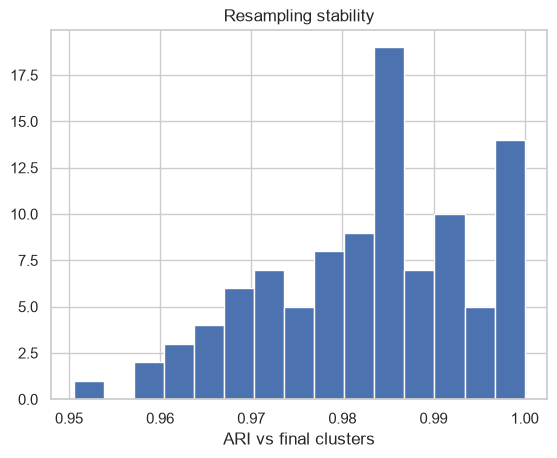

In [8]:
rng = np.random.default_rng(0)
n = len(X)
boot = []
for i in range(100):
    idx = rng.choice(n, size=int(0.8 * n), replace=False)
    lab = KMeans(n_clusters=K, n_init=10, random_state=i).fit(X.iloc[idx]).labels_
    boot.append(adjusted_rand_score(ref[idx], lab))
print(f"80% subsamples, 100 runs: mean ARI = {np.mean(boot):.3f}, min = {np.min(boot):.3f}")
plt.hist(boot, bins=15); plt.xlabel("ARI vs final clusters"); plt.title("Resampling stability")
plt.savefig("../figures/07_resampling_stability.png", dpi=150); plt.show()

ARI:           0.406
NMI:           0.551
Homogeneity:   0.542
Completeness:  0.559


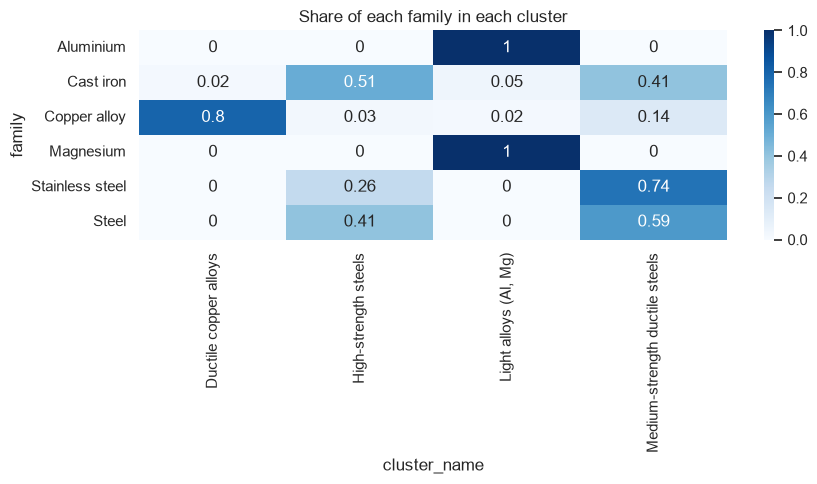

In [9]:
fam = meta["family"]
print("ARI:          ", round(adjusted_rand_score(fam, ref), 3))
print("NMI:          ", round(normalized_mutual_info_score(fam, ref), 3))
print("Homogeneity:  ", round(homogeneity_score(fam, ref), 3))
print("Completeness: ", round(completeness_score(fam, ref), 3))

ct = pd.crosstab(meta["family"], meta["cluster_name"], normalize="index").round(2)
plt.figure(figsize=(9, 5))
sns.heatmap(ct, annot=True, cmap="Blues", vmin=0, vmax=1)
plt.title("Share of each family in each cluster")
plt.tight_layout(); plt.savefig("../figures/07_family_vs_cluster.png", dpi=150); plt.show()

In [10]:
def variant(name, cols=None, Xv=None, rows=None):
    Xs = Xv if Xv is not None else X[cols]
    if rows is not None:
        Xs = Xs.loc[rows]
    lab = KMeans(n_clusters=K, n_init=20, random_state=42).fit_predict(Xs)
    return {"variant": name, "n_rows": len(Xs),
            "silhouette": round(silhouette_score(Xs, lab), 3),
            "ARI vs final": round(adjusted_rand_score(meta.loc[Xs.index, "cluster"], lab), 3)}

X_nolog = pd.DataFrame(StandardScaler().fit_transform(meta[CORE]), columns=CORE, index=meta.index)
not_imputed = meta.index[~meta["elongation_imputed"].astype(bool)]

rows = [
    variant("all 5 features (reference)", CORE),
    variant("drop yield strength", [c for c in CORE if c != "yield_strength_MPa"]),
    variant("drop elongation", [c for c in CORE if c != "elongation_pct"]),
    variant("drop density", [c for c in CORE if c != "density_g_cm3"]),
    variant("drop modulus", [c for c in CORE if c != "youngs_modulus_GPa"]),
    variant("strength + elongation only (drop density and modulus)",
            ["tensile_strength_MPa", "yield_strength_MPa", "elongation_pct"]),
    variant("no log transform (standardize only)", Xv=X_nolog),
    variant("exclude KNN-imputed elongation rows", CORE, rows=not_imputed),
]
display(pd.DataFrame(rows).set_index("variant"))

,n_rows,silhouette,ARI vs final
variant,,,
all 5 features (reference),1235,0.424,1.000
drop yield strength,1235,0.434,0.785
drop elongation,1235,0.527,0.813
drop density,1235,0.404,0.908
drop modulus,1235,0.370,0.566
strength + elongation only (drop density and modulus),1235,0.396,0.714
no log transform (standardize only),1235,0.489,0.471
exclude KNN-imputed elongation rows,1104,0.426,0.994


## Evaluation summary
| Evidence | Result |
|---|---|
| Chosen K | 4 |
| Silhouette / Davies-Bouldin / Calinski-Harabasz | 0.424 / 0.795 / 1218.5 |
| Reproducibility (20 starts, 10 seeds) | mean ARI 0.993, min 0.984 |
| Resampling (100 x 80% subsets) | mean ARI 0.984, min 0.951 |
| Agreement with families | ARI 0.406, NMI 0.551, homogeneity 0.542, completeness 0.559 |
| Excluding imputed-elongation rows | ARI 0.994 |

**Interpretation.** The four clusters (light alloys, ductile copper alloys, medium-strength steels, high-strength steels) are reproducible and stable under resampling. Separation is moderate (silhouette 0.42): strength and ductility vary continuously within steel, so the boundary between the two steel clusters is a convention, as shown by the disagreement with hierarchical clustering. Clusters follow mechanical similarity rather than composition, so stainless steel and cast iron are spread across the steel clusters. The result is robust to dropping density, elongation or yield, and to removing imputed values, but sensitive to the log transform and to modulus, which is a coarse family-level value in the source data.